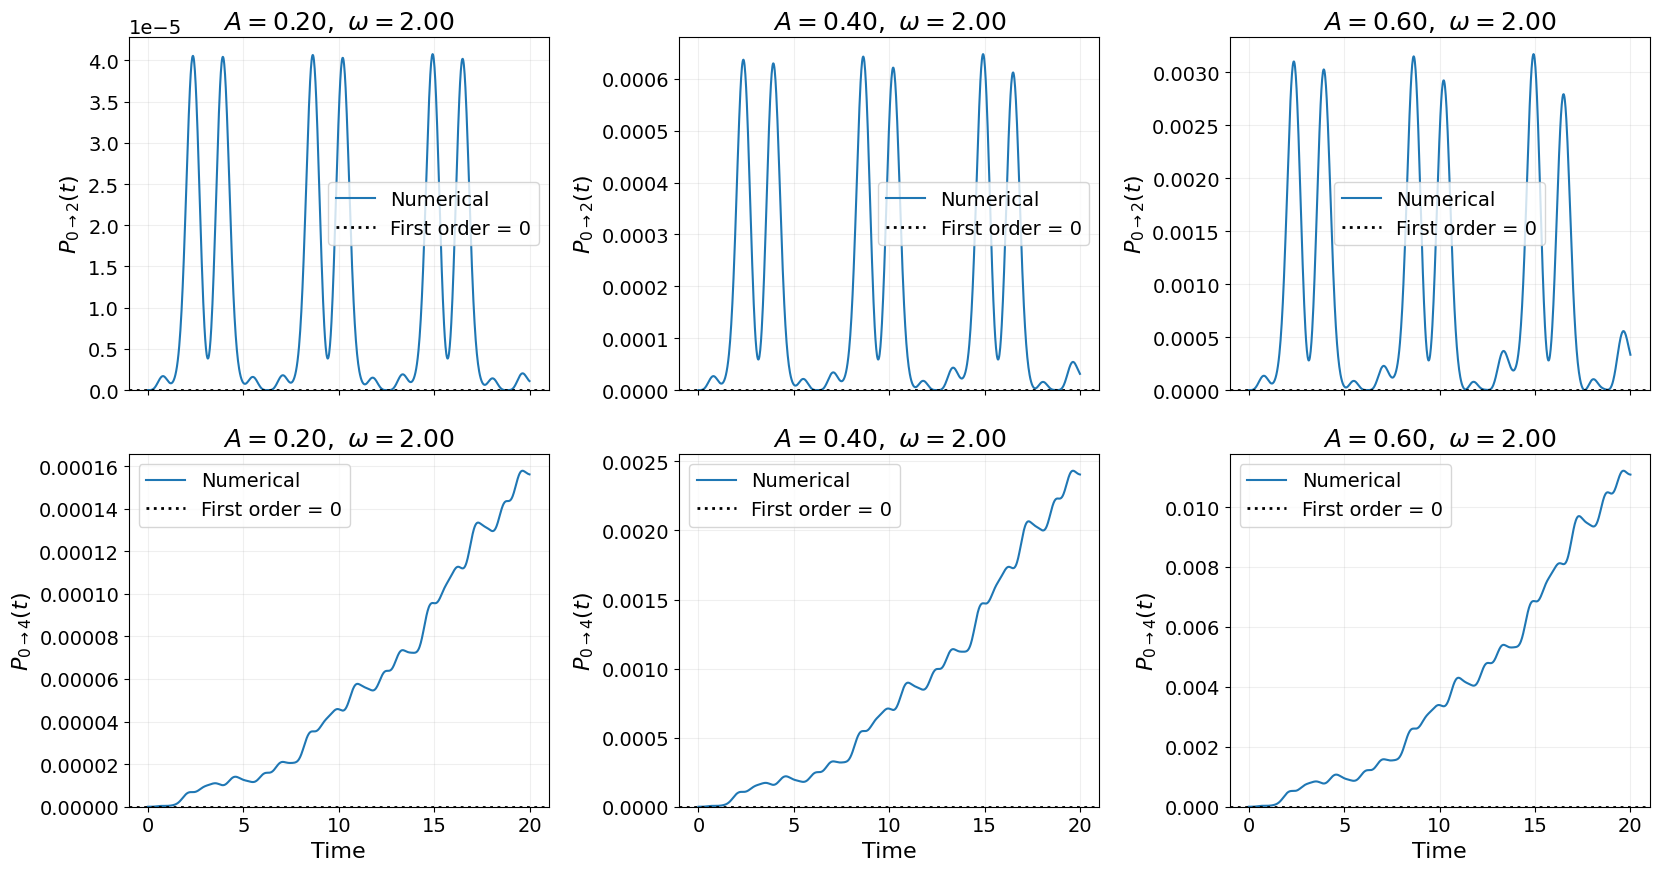

In [5]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})


folder = Path.cwd()
if not (folder / "harmonic.py").exists():
    folder = folder.parent
sys.path.insert(0, str(folder))

from harmonic import HarmonicOscillator

# Parameters
omega = 2.0
A_values = [0.2, 0.4, 0.6]
n = 128
L = 12
dt = 0.02
tmax = 20

ho = HarmonicOscillator(boundary=(-L, L), n=n)
_, basis = ho.eigenstates()

phi0 = basis[:, 0]
phi2 = basis[:, 2]
phi4 = basis[:, 4]

times = np.linspace(0, tmax, int(np.ceil(tmax / dt)) + 1)

fig, axes = plt.subplots(
    2, 3, figsize=(17, 9), sharex=True
)

for col, A in enumerate(A_values):
    psi = phi0.copy()
    P2 = np.zeros(len(times))
    P4 = np.zeros(len(times))

    for i in range(1, len(times)):
        psi = ho.time_evolution(
            [times[i]],
            omega=omega,
            A=A,
            psi0=psi,
            t0=times[i - 1]
        )

        P2[i] = np.abs(np.vdot(phi2, psi))**2
        P4[i] = np.abs(np.vdot(phi4, psi))**2

    # Top row: second excited state
    # Bottom row: fourth excited state
    for row, (level, P) in enumerate([(2, P2), (4, P4)]):
        ax = axes[row, col]

        ax.plot(times, P, label="Numerical")
        ax.axhline(
            0, color="black", linestyle=":", linewidth=2,
            label="First order = 0"
        )

        ax.set_title(rf"$A={A:.2f},\ \omega={omega:.2f}$")
        ax.set_ylabel(rf"$P_{{0\to{level}}}(t)$")
        ax.set_ylim(bottom=0)
        ax.legend()
        ax.grid(alpha=0.2)

    axes[1, col].set_xlabel("Time")

plt.tight_layout()
plt.show()